# 07 集成学习

本篇对应课程目录 `07_集成学习`，依据教师笔记《集成学习.md》整理。主线是：先用多个基学习器降低方差或纠正错误，再学习随机森林、AdaBoost、GBDT 和 XGBoost 的思想、公式与实践方式。

资料：[机器学习课程网盘](https://pan.baidu.com/s/1NmWli9KoAeYtlpXTzhw-Jg?pwd=1234)，提取码 `1234`。

本轮已读取教师 Markdown 和配图，未取得课程代码压缩包及 CSV，因此不报告课程 Titanic 或红酒品质的真实成绩。内置数据上的随机森林、AdaBoost、XGBoost，以及课程十点数据的 GBDT 手算代码均已验证；Titanic 和红酒品质部分提供了需要实际 CSV 的实现。所有图片都嵌入本 Notebook 附件，不依赖独立图片文件。

课程原文中的部分 API 已过时，例如 `AdaBoostClassifier(base_estimator=...)` 在新版本应写成 `estimator=...`，`max_features="auto"` 在新版本随机森林中也不再使用。本篇以 sklearn 1.9.1、XGBoost 3.4.1 的写法为准。

## 学习路线

| 阶段 | 关键问题 | 核心结论 |
| --- | --- | --- |
| 集成思想 | 为什么多个模型可能更强？ | 让错误相互抵消，组合互补信息 |
| Bagging | 怎样制造有差异的基学习器？ | 有放回抽样、并行训练、平权投票/平均 |
| 随机森林 | 决策树怎样进一步去相关？ | 样本和节点特征都随机，树做基学习器 |
| Boosting | 怎样逐轮修正难样本？ | 串行训练、提高错分样本权重、加权组合 |
| AdaBoost | 如何计算分类器权重？ | 错误率越低，$α$ 越大 |
| GBDT | 回归树每轮拟合什么？ | 损失函数的负梯度；平方损失时就是残差 |
| XGBoost | 怎样让 GBDT 更快、更稳？ | 二阶泰勒展开、正则化、分裂增益 |

先区分两组词：**基学习器**是参与组合的单个模型，**集成学习器**是它们组合后的整体。基学习器可以是树、线性模型或其他能输出预测的模型。基学习器不一定是理论意义上的弱学习器；AdaBoost 的二分类推导要求基分类器在当前加权分布上的错误率小于 0.5。

## 1. 集成学习：从多个答案得到一个答案

传统模型试图直接找到一个分类器或回归器。集成学习训练多个模型，再把预测组合起来。分类可用多数投票或概率平均，回归常用预测均值；Boosting 还会给不同模型不同权重。

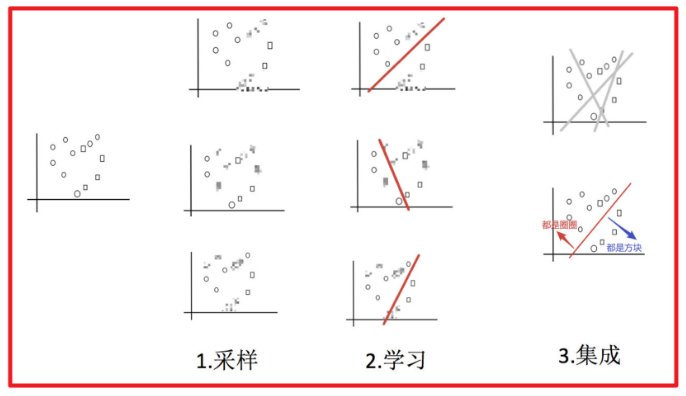

单个模型的错误可能来自偏差、方差和噪声。组合模型主要能降低方差和部分偏差，不能消除标签错误或数据分布变化。

如果 $M$ 个回归器方差相同为 $\sigma^2$，任意两个模型的相关系数近似为 $\rho$，平均预测的方差为：

$$\operatorname{Var}\left(\frac1M\sum_{m=1}^{M}f_m\right)=\sigma^2\left(\rho+\frac{1-\rho}{M}\right)$$

当模型独立时 $\rho=0$，增加模型数会明显降低方差；当模型完全相同时 $\rho=1$，平均没有收益。因此随机森林既要让树足够强，也要让树之间保持差异。模型越多并非无限提升，相关错误、计算成本和数据偏差仍然存在。

### 1.1 Bagging 与 Boosting 的先验差异

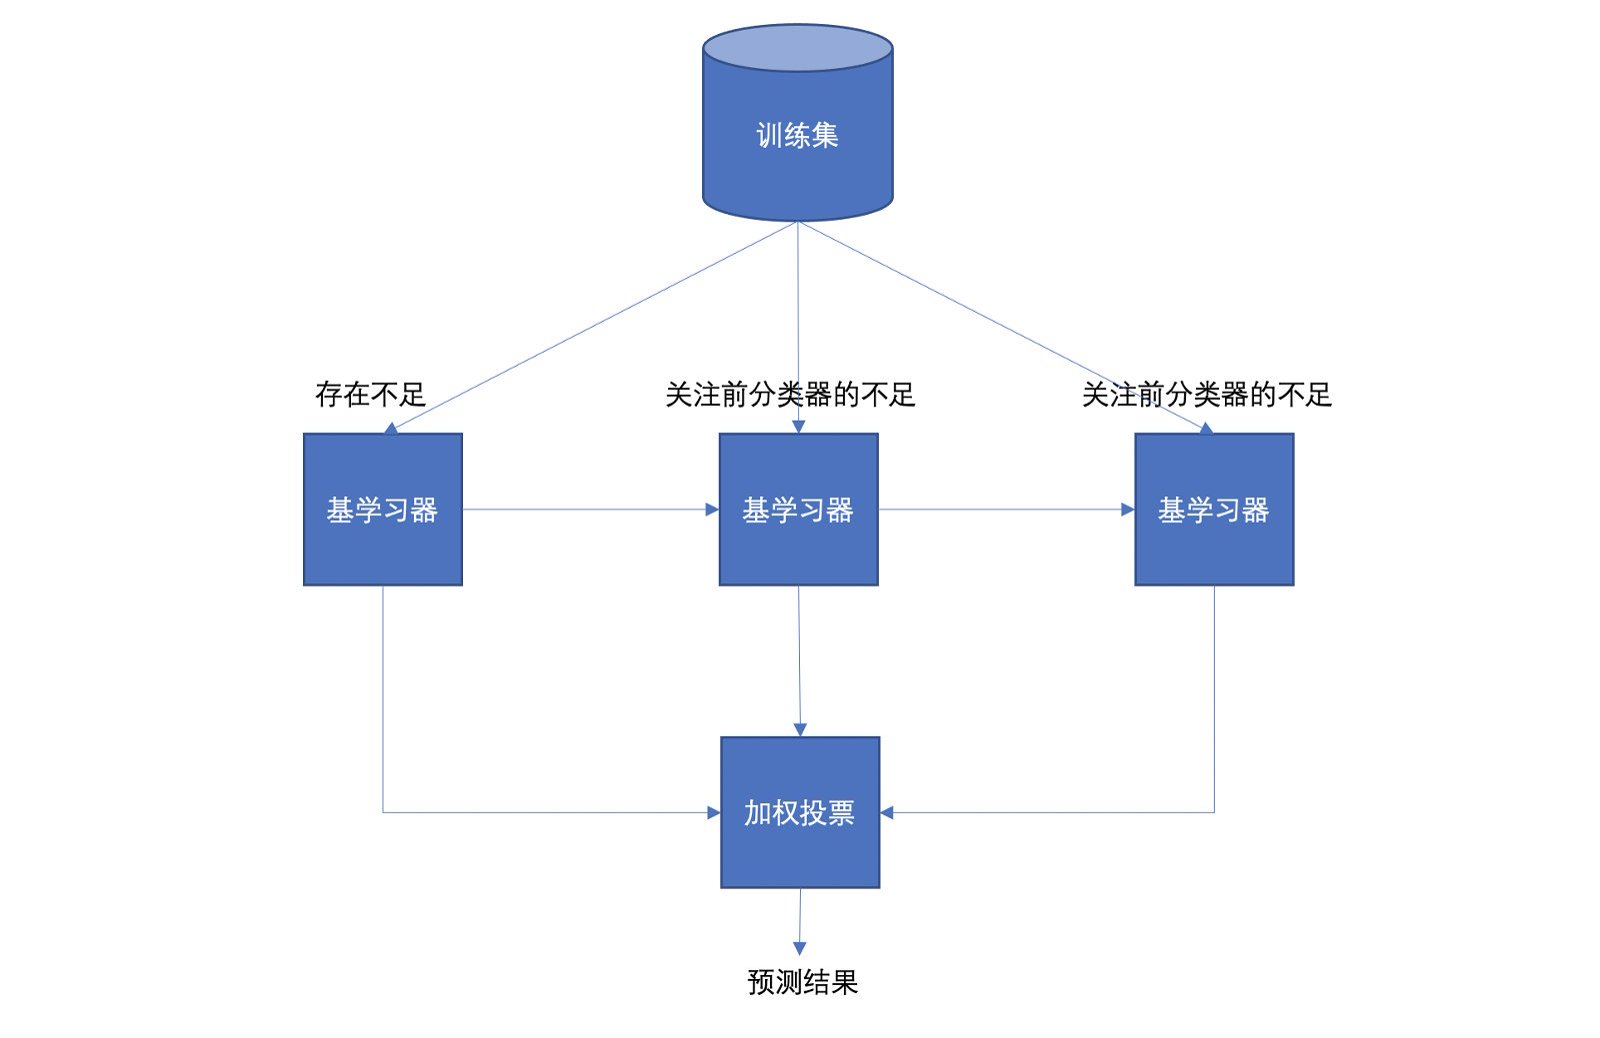

| 对比维度 | Bagging | Boosting |
| --- | --- | --- |
| 数据 | 对训练集有放回抽样得到多个样本集 | 通常重复使用全部训练样本，但改变关注权重或拟合目标 |
| 训练顺序 | 基学习器互不依赖，可并行 | 后一个学习器依赖前一个的错误，通常串行 |
| 组合 | 分类平权投票，回归平均 | 按基学习器表现加权组合 |
| 主要作用 | 降低方差、提升稳定性 | 逐轮降低偏差，也可能放大噪声 |
| 代表算法 | Bagging、随机森林 | AdaBoost、GBDT、XGBoost |

表中的分类投票是概念示意，具体库可能采用概率平均；回归没有多数类投票。AdaBoost 通过样本权重体现关注重点，GBDT 把当前模型对应的负梯度作为下一轮目标；随机梯度提升也可对样本进行子采样。

## 2. Bagging：样本有放回，模型平权组合

设训练集有 $N$ 条样本。每棵基学习器都从原数据有放回抽取 $N$ 次，得到一个 bootstrap 样本集；同一行可能被抽中多次，也可能完全没有被抽中。然后对每个样本集训练一个模型。

分类时：

$$\hat y=\operatorname{mode}\{h_1(x),h_2(x),\ldots,h_M(x)\}$$

回归时：

$$\hat y=\frac1M\sum_{m=1}^{M}h_m(x)$$

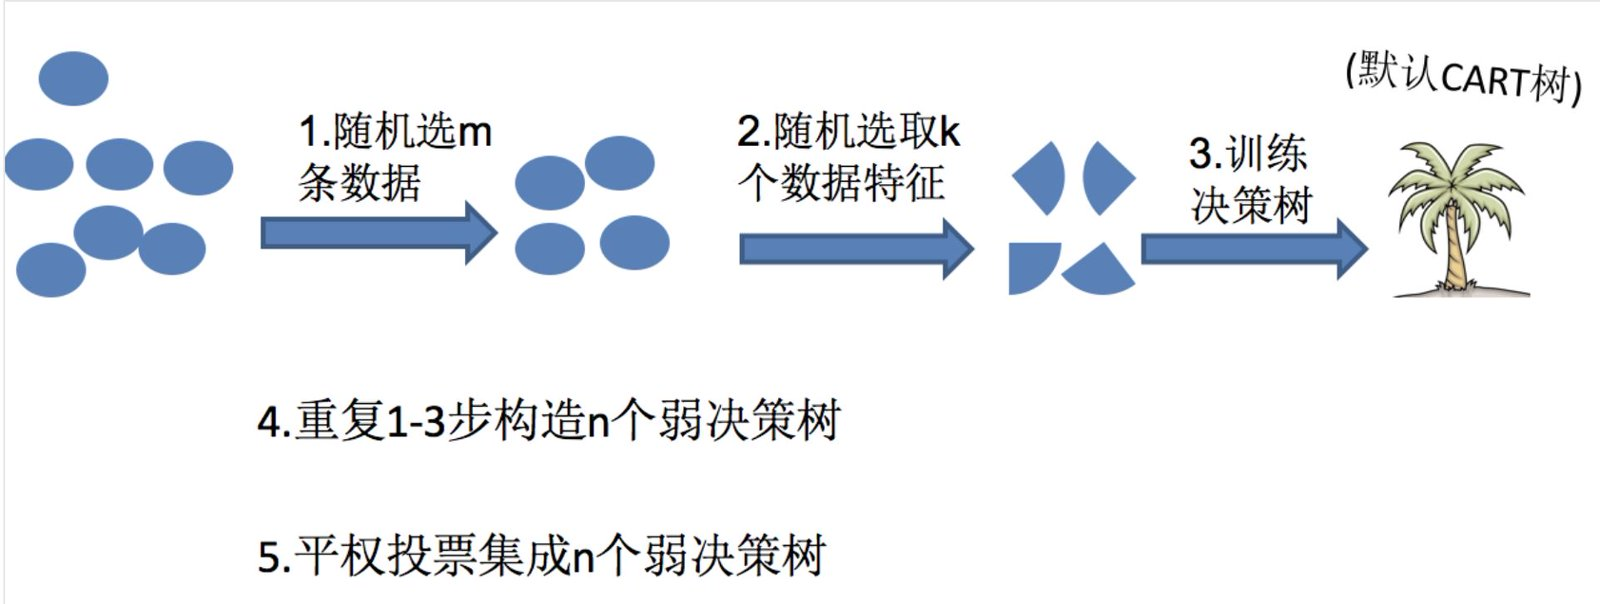

*这张图在 Bagging 样本抽样的基础上增加了特征随机性，具体机制见下一节随机森林。普通 Bagging 不要求在每个树节点随机抽特征。*

有放回抽样的一个可计算结论是：某条固定样本一次也没有被抽中的概率为 $\left(1-\frac1N\right)^N$，当 N 较大时约为 $e^{-1}=0.3679$。所以一棵树约有 63.2% 的不同样本、约 36.8% 的 OOB（out-of-bag）样本。OOB 样本可用于近似验证，但它不是独立测试集。

```python
import numpy as np

rng = np.random.default_rng(22)
n = 10
for tree_id in range(3):
    sampled = rng.choice(n, size=n, replace=True)
    oob = np.setdiff1d(np.arange(n), np.unique(sampled))
    print("树", tree_id + 1, "抽样索引：", sampled, "OOB索引：", oob)
print("单个样本未被抽中的概率：", (1 - 1 / n) ** n)
print("期望独立样本数：", n * (1 - (1 - 1 / n) ** n))
```

### 2.1 硬投票和概率平均不是同一件事

硬投票先把每棵树的概率变成类别，再数票；软投票直接平均概率。两者在类别不平衡、树的置信度不同或票数很少时可能不同。

```python
import numpy as np

# 3 棵树，对同一个样本的 [P(0), P(1)]
tree_probs = np.array([[0.51, 0.49], [0.51, 0.49], [0.0, 1.0]])
hard_labels = tree_probs.argmax(axis=1)
hard_vote = np.bincount(hard_labels, minlength=2).argmax()
soft_vote = tree_probs.mean(axis=0).argmax()
print("各树硬标签：", hard_labels, "硬投票：", hard_vote)
print("平均概率：", tree_probs.mean(axis=0), "概率平均后选择：", soft_vote)
```

上例中两棵树以很小优势投 0，一棵树高置信度投 1；硬投票是 0，平均概率是 `[0.34, 0.66]`，软投票是 1。sklearn 的 `RandomForestClassifier.predict_proba()` 平均各树的类别概率，`predict()` 再选择平均概率最大的类，因此它可能与各树硬标签的多数票不同。

## 3. 随机森林：Bagging 加上特征随机性

随机森林把决策树作为基学习器，训练每棵树时使用两层随机性：

1. 对样本有放回抽样，形成该树的训练集；
2. 在每个节点只从一部分候选特征中寻找最佳切分；
3. 用 CART 方式生长树，按参数或停止条件控制复杂度；
4. 分类多数投票或概率平均，回归取各树输出均值。

经典随机森林常采用较充分生长的树，依赖抽样和组合降低方差；这不代表永远不会过拟合。样本与特征随机性可以降低相关性，不能保证树之间严格独立，也不能保证准确率一定提高。仍需要验证 `max_depth`、`min_samples_leaf`、`max_features` 和树数量。

随机抽样训练集是为了让树看到不同样本；有放回抽样允许样本重复并留下 OOB 子集。若所有树使用完全相同的样本、特征和参数，它们会高度相似，投票不能有效减少相关误差。

### 3.1 随机森林 API

```python
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=200,          # 树的数量
    criterion="gini",         # 也可使用 "entropy" 或 "log_loss"
    max_features="sqrt",      # 每个节点可考察的特征数策略
    bootstrap=True,            # 是否有放回抽样
    max_depth=None,
    min_samples_leaf=2,
    oob_score=True,
    random_state=22,
    n_jobs=-1,
)
```

| 参数 | 作用 | 选择提示 |
| --- | --- | --- |
| `n_estimators` | 森林中树的数量 | 增加后通常趋于稳定，但成本增加 |
| `max_features` | 每个节点考察的特征子集 | `sqrt` 常用于分类，`1.0` 表示全部 |
| `bootstrap` | 是否使用有放回样本 | 关闭后不再是标准 Bagging 抽样 |
| `oob_score` | 是否计算 OOB 估计 | 只有 `bootstrap=True` 才有意义 |
| `max_depth`、`min_samples_leaf` | 单棵树复杂度 | 用验证或交叉验证选择 |
| `class_weight` | 类别权重 | 不平衡任务可比较 `"balanced"` |
| `n_jobs` | 并行线程数 | `-1` 使用可用 CPU；复现实验仍固定 `random_state` |

旧课件中的 `max_features="auto"` 在新版本已移除，分类任务想表达旧默认行为直接写 `"sqrt"`；当前默认树数为 100，课程中的默认 10 是旧版本。`min_impurity_split` 已移除，可通过深度、最小叶子样本数和 `min_impurity_decrease` 控制生长，但后者衡量的是加权不纯度降低，语义不同。`min_samples_leaf` 是生长时的约束，不是“先长出小叶子再和兄弟剪掉”。

### 3.2 随机森林实战与 OOB

下面用 sklearn 内置乳腺癌数据比较一棵树、普通 Bagging 和交叉验证选出的随机森林。测试集只在最后报告；CV 和 OOB 只使用训练集。

```python
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, stratify=data.target, random_state=22)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=22)
search = GridSearchCV(
    RandomForestClassifier(bootstrap=True, max_features="sqrt",
                           random_state=22, n_jobs=1),
    param_grid={"n_estimators": [80, 160], "max_depth": [4, None],
                "min_samples_leaf": [1, 3]},
    scoring="f1_macro", cv=cv, n_jobs=1, refit=True)
search.fit(X_train, y_train)

models = {
    "Single tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=2, random_state=22),
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=6, min_samples_leaf=2),
        n_estimators=160, bootstrap=True, max_features=1.0,
        random_state=22, n_jobs=1),
    "Random forest (CV)": search.best_estimator_,
}
rows = []
for name, model in models.items():
    if name != "Random forest (CV)":
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"model": name,
                 "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
                 "test_accuracy": accuracy_score(y_test, pred),
                 "test_macro_f1": f1_score(y_test, pred, average="macro")})
forest_scores = pd.DataFrame(rows)
print("样本数 train/test：", len(y_train), len(y_test))
print("森林最佳参数：", search.best_params_)
print("森林最佳CV macro-F1：", search.best_score_)
print(forest_scores.round(6).to_string(index=False))

# OOB只用训练数据；这一步不再根据测试集选择参数
rf = search.best_estimator_.set_params(oob_score=True)
rf.fit(X_train, y_train)
print("OOB accuracy：", rf.oob_score_)
forest_result = {"train_size": len(y_train), "test_size": len(y_test),
                 "best_params": search.best_params_, "cv_macro_f1": search.best_score_,
                 "oob_accuracy": rf.oob_score_, "scores": rows}
```

| 模型 | 训练 accuracy | 测试 accuracy | 测试 macro-F1 |
| --- | --- | --- | --- |
| Single tree | 0.986813 | 0.877193 | 0.870455 |
| Bagging | 0.993407 | 0.938596 | 0.933693 |
| Random forest (CV) | 0.989011 | 0.938596 | 0.933693 |

| 随机森林训练信息 | 实际值 |
| --- | --- |
| train / test | 455 / 114 |
| CV选中参数 | {'max_depth': 4, 'min_samples_leaf': 1, 'n_estimators': 80} |
| 最佳CV macro-F1 | 0.969398 |
| OOB accuracy | 0.951648 |

本轮固定切分的结果：单树测试准确率约 `0.8772`，Bagging 与随机森林约 `0.9386`；森林的 3 折 CV macro-F1 约 `0.9694`，OOB accuracy 约 `0.9516`。这些是内置数据的一次切分结果，不代表所有数据集都会提高同样幅度。

这三种模型用于演示比较，没有根据测试分数进一步挑模型。OOB 和 CV 的评分指标不同，不能直接把 0.9516 与 0.9694 比大小。若在森林前使用全训练集拟合的预处理器，严格的 OOB 验证还可能受这些预处理统计量影响；本例为无缺失的内置数值数据。

特征重要性可以作为探索工具，不能自动解释因果关系；随机森林的 MDI 还可能偏向取值多、可切分位置多的特征。解释模型时可以在独立验证集上补充 permutation importance。

## 4. Titanic：比较单树、随机森林和 GBDT

课程原案例人工选择 `Pclass、Age、Sex`，然后比较决策树、随机森林和 GBDT。这里保留特征白名单，避免把 `boat、body` 等事后字段泄漏给模型。不同课程 CSV 的大小写、列名和缺失值可能不同，先打印 `df.columns` 再映射。

本教学案例约定存活为正类：accuracy 看总体正确率，F1 看 precision/recall 的折中，ROC-AUC 使用存活概率而不是硬标签。真实使用时，正类和主指标应由具体预测目标及误判代价决定。

课程代码先在全量表上填补年龄再切分，这会让测试集分布参与填补器。下面用 Pipeline 让填补、one-hot 和模型只从训练集学习。

### 4.1 安全 Pipeline

```python
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

def compare_titanic(df):
    df = df.copy()
    df.columns = [str(c).strip().lower() for c in df.columns]
    required = {"pclass", "age", "sex", "survived"}
    if not df.columns.is_unique or not required.issubset(df.columns):
        raise ValueError("请检查列名，需要 pclass/age/sex/survived，且列名不能重复")
    raw_target = df["survived"]
    target = pd.to_numeric(raw_target, errors="coerce")
    if (raw_target.notna() & ~target.isin([0, 1])).any():
        raise ValueError("存活标签必须先明确映射为0/1")
    labeled = target.notna()
    X = df.loc[labeled, ["pclass", "age", "sex"]].copy()
    y = target.loc[labeled].astype(int)
    for col in ["pclass", "age"]:
        X[col] = pd.to_numeric(X[col], errors="coerce")
    sex = X["sex"].astype("string").str.strip().str.lower()
    X["sex"] = sex.astype(object).where(sex.notna() & sex.ne(""), np.nan)
    if y.nunique() != 2:
        raise ValueError("带标签数据必须包含两类")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=22)
    preprocessing = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), ["pclass", "age"]),
        ("cat", Pipeline([
            ("fill", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), ["sex"]),
    ])
    candidates = {
        "决策树": DecisionTreeClassifier(max_depth=6, min_samples_leaf=3, random_state=22),
        "随机森林": RandomForestClassifier(n_estimators=160, max_depth=6,
                        min_samples_leaf=3, max_features="sqrt", random_state=22, n_jobs=1),
        "GBDT": GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                        max_depth=2, min_samples_leaf=3, random_state=22),
    }
    fitted, records = {}, []
    for name, classifier in candidates.items():
        pipe = Pipeline([("preprocess", clone(preprocessing)), ("model", classifier)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        column = list(pipe.named_steps["model"].classes_).index(1)
        prob = pipe.predict_proba(X_test)[:, column]
        print(name, "\n", classification_report(y_test, pred, digits=4, zero_division=0))
        records.append({"模型": name, "accuracy": accuracy_score(y_test, pred),
                        "F1(存活)": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, prob)})
        fitted[name] = pipe
    return pd.DataFrame(records), fitted

# 下载课程CSV后修改实际路径；本例参数为固定基线
titanic = pd.read_csv("data/泰坦尼克号.csv")
print(titanic.shape, titanic.columns.tolist())
scores, fitted_titanic = compare_titanic(titanic)
print(scores)
```

`pclass` 和 `age` 用训练集内中位数填补，`sex` 用训练集内众数填补后 one-hot。决策树、森林和 GBDT 都能处理数值输入，但仍需处理字符串类别与缺失值。

课程 CSV 未下载成功，本轮用明确构造的合成表检查了大小写统一、缺失填补、未知类别和三种模型的管道结构；合成数据成绩不作为 Titanic 真实效果。

## 5. AdaBoost：把注意力放到难样本

AdaBoost 在每轮选择一个基分类器 $h_t$，按它的加权错误率计算模型权重，再提高错分样本的权重。

二分类标签写为 $y_i,h_t(x_i)\in\{-1,+1\}$。第 t 轮的加权错误率：

$$\epsilon_t=\sum_{i=1}^{N}D_t(i)\,\mathbf1[h_t(x_i)\ne y_i]$$

分类器权重：

$$\alpha_t=\frac12\ln\frac{1-\epsilon_t}{\epsilon_t}$$

样本权重更新并归一化：

$$D_{t+1}(i)=\frac{D_t(i)\exp[-\alpha_t y_i h_t(x_i)]}{Z_t}$$

正确样本的指数因子为 $e^{-\alpha_t}$，错分样本为 $e^{\alpha_t}$，因此错分样本下一轮占比上升。最终强分类器：

$$H(x)=\operatorname{sign}\left(\sum_{t=1}^{T}\alpha_t h_t(x)\right)$$

要求 $0<\epsilon_t<0.5$ 才能得到正的有效权重。错误率接近 0 时权重会很大，噪声点可能主导后续学习；错误率不小于 0.5 时要换方向、换基学习器或停止。

### 5.1 手算三个弱分类器

课程给出 10 个按 x 排序的样本，标签为 `+1/-1`。第一轮权重均为 0.1，阈值候选是相邻值中点。下面代码明确把阈值方向也作为候选，按加权错误率最小且先出现的规则处理同分。

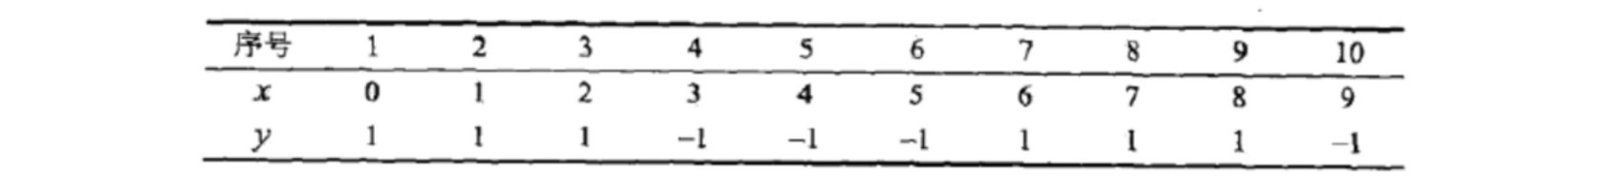

```python
import numpy as np
import pandas as pd

x = np.arange(10, dtype=float)
y = np.array([1, 1, 1, -1, -1, -1, 1, 1, 1, -1])
weights = np.full(len(y), 1 / len(y))
thresholds = (x[:-1] + x[1:]) / 2
F = np.zeros(len(y), dtype=float)
ada_rounds, weight_history = [], [weights.copy()]

for round_id in range(1, 4):
    best = None
    # 同分时保留先枚举者，确保结果可复现
    for threshold in thresholds:
        for polarity in [1, -1]:
            pred = polarity * np.where(x <= threshold, 1, -1)
            error = float(weights[pred != y].sum())
            if best is None or error < best[0] - 1e-12:
                best = (error, threshold, polarity, pred)
    error, threshold, polarity, pred = best
    if not 0 < error < 0.5:
        raise ValueError("教学公式要求0<加权错误率<0.5；极端情况需单独处理")
    alpha = 0.5 * np.log((1 - error) / error)
    weights = weights * np.exp(-alpha * y * pred)
    weights = weights / weights.sum()
    F += alpha * pred
    ensemble_pred = np.where(F >= 0, 1, -1)
    ada_rounds.append({"round": round_id, "threshold": float(threshold),
                       "polarity": polarity, "weighted_error": error,
                       "alpha": float(alpha),
                       "ensemble_train_error": float(np.mean(ensemble_pred != y))})
    weight_history.append(weights.copy())

print(pd.DataFrame(ada_rounds).round(6).to_string(index=False))
weight_table = pd.DataFrame(np.asarray(weight_history).T,
    columns=["initial", "after_round1", "after_round2", "after_round3"])
weight_table.insert(0, "x", x.astype(int))
print(weight_table.round(6).to_string(index=False))
print("最终训练标签：", ensemble_pred)
```

本轮得到阈值序列 `2.5 → 8.5 → 5.5`，错误率约 `0.3 → 0.214286 → 0.181818`，模型权重约 `0.423649 → 0.649641 → 0.752039`。前两棵树在阈值左侧预测 +1，第三棵在左侧预测 -1。第三轮后训练集被全部正确分类；这只是教学表上的拟合结果。

第一轮错误的是 x=6、7、8，归一化后各占 `1/6≈0.166667`；其他七条各占 `1/14≈0.071429`。第二轮错误的是 x=3、4、5，加权错误率为 `3/14≈0.214286`，不能仍然用错误条数除以 10。讲义第二轮部分错误率与编号混用了近似值，本篇代码按完整精度计算。

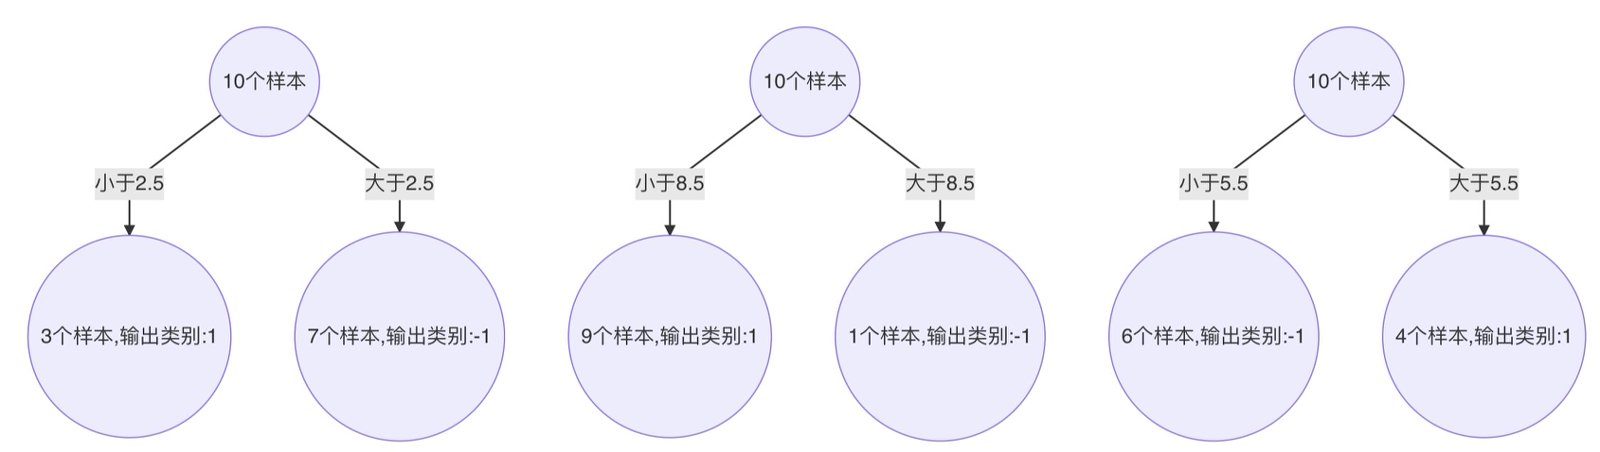

*三棵树进行带权符号投票。它们是分类树桩，不是下面 GBDT 的残差回归树。*

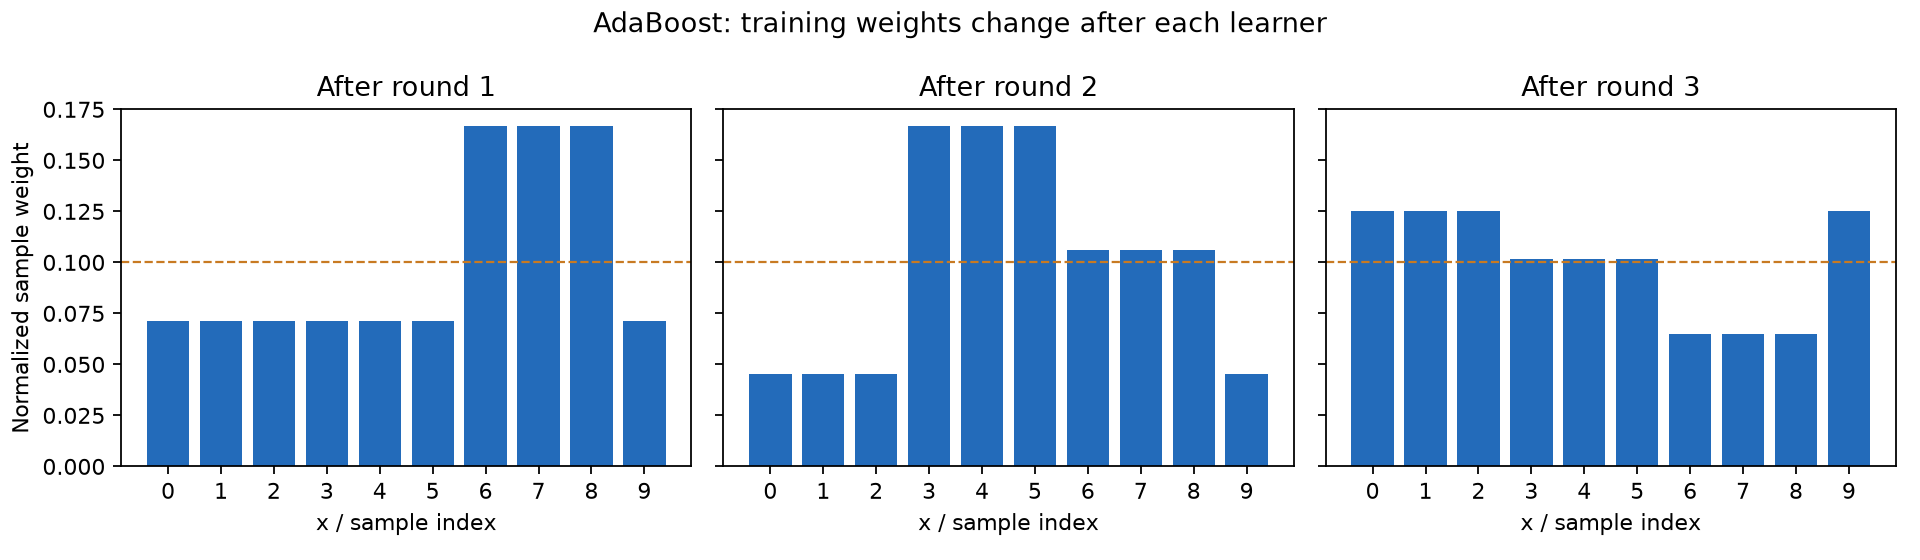

图中高柱表示下一轮应重点关注的样本。集成训练误差继续下降时，验证误差可能因为噪声和过拟合而上升，`n_estimators` 和学习率仍需验证。

### 5.2 AdaBoost 的二分类实践

课程使用葡萄酒数据的两个特征 `Alcohol、Hue` 区分原始类别 2 和 3，单层决策树作为基学习器。新版本 API 使用 `estimator`，并且标签编码要在训练数据定义后检查。

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

wine = load_wine()
feature_ids = [wine.feature_names.index("alcohol"), wine.feature_names.index("hue")]
mask = wine.target != 0  # 原始Wine的第1类；内置编码为0
X = wine.data[mask][:, feature_ids]
y = wine.target[mask] - 1  # 原始第2/3类映射为0/1；此处已确认内置编码
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=1)
stump = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=0)
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=0),
    n_estimators=500, learning_rate=0.1, random_state=0)
wine_rows = []
for name, model in [("Decision stump", stump), ("AdaBoost", ada)]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    wine_rows.append({"model": name,
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, pred),
        "test_macro_f1": f1_score(y_test, pred, average="macro"),
        "test_auc": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])})
wine_ada_result = {"train_size": len(y_train), "test_size": len(y_test), "scores": wine_rows,
                   "fitted_boosting_rounds": len(ada.estimators_)}
print(pd.DataFrame(wine_rows).round(6).to_string(index=False))

xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-0.3, X[:, 0].max()+0.3, 240),
                     np.linspace(X[:, 1].min()-0.1, X[:, 1].max()+0.1, 240))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, name, model in zip(axes, ["Decision stump", "AdaBoost"], [stump, ada]):
    pred_grid = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, pred_grid, levels=[-0.5,0.5,1.5], colors=["#dce9ff","#ffe3cb"])
    ax.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap="coolwarm", s=22, marker="o", label="Train")
    ax.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap="coolwarm", s=40, marker="x", label="Test")
    ax.set(title=name, xlabel="Alcohol", ylabel="Hue")
    ax.legend(loc="upper left")
fig.suptitle("Wine cultivar classes 2 and 3 | two-feature teaching example")
fig.tight_layout()
plt.show()
```

| 模型 | 训练 accuracy | 测试 accuracy | 测试 macro-F1 | 测试 AUC |
| --- | --- | --- | --- | --- |
| Decision stump | 0.887324 | 0.895833 | 0.887588 | 0.877495 |
| AdaBoost | 0.985915 | 0.958333 | 0.956443 | 0.989111 |

训练 / 测试样本数：71 / 48，实际训练 500 个基分类器。

本轮用 sklearn 内置 Wine 数据复现“两类、两特征、树桩 vs AdaBoost”结构：决策树桩测试 accuracy 约 `0.8958`，AdaBoost 约 `0.9583`。本例采用分层切分及当前版本，未取得课程 `wine.data`，因此不能把数字当成课程 CSV 原案例成绩。讲义将 Wine 产区分类与 Wine Quality 品质评分的背景混在一起；这里的目标是原始 Wine 第 2、3 类产区，没有品质标签。无表头的 `wine.data` 若用 pandas 读取，应显式写 `header=None`，否则第一行会被误作列名。

上面的手算是经典二分类 AdaBoost 形式；当前 sklearn 的分类实现采用 SAMME，其权重约定与多分类推导有关，不能要求 `estimator_weights_` 与手算的每个 $\alpha_t$ 完全相同。本例使用当前 API，不指定已移除的 `algorithm="SAMME.R"`。

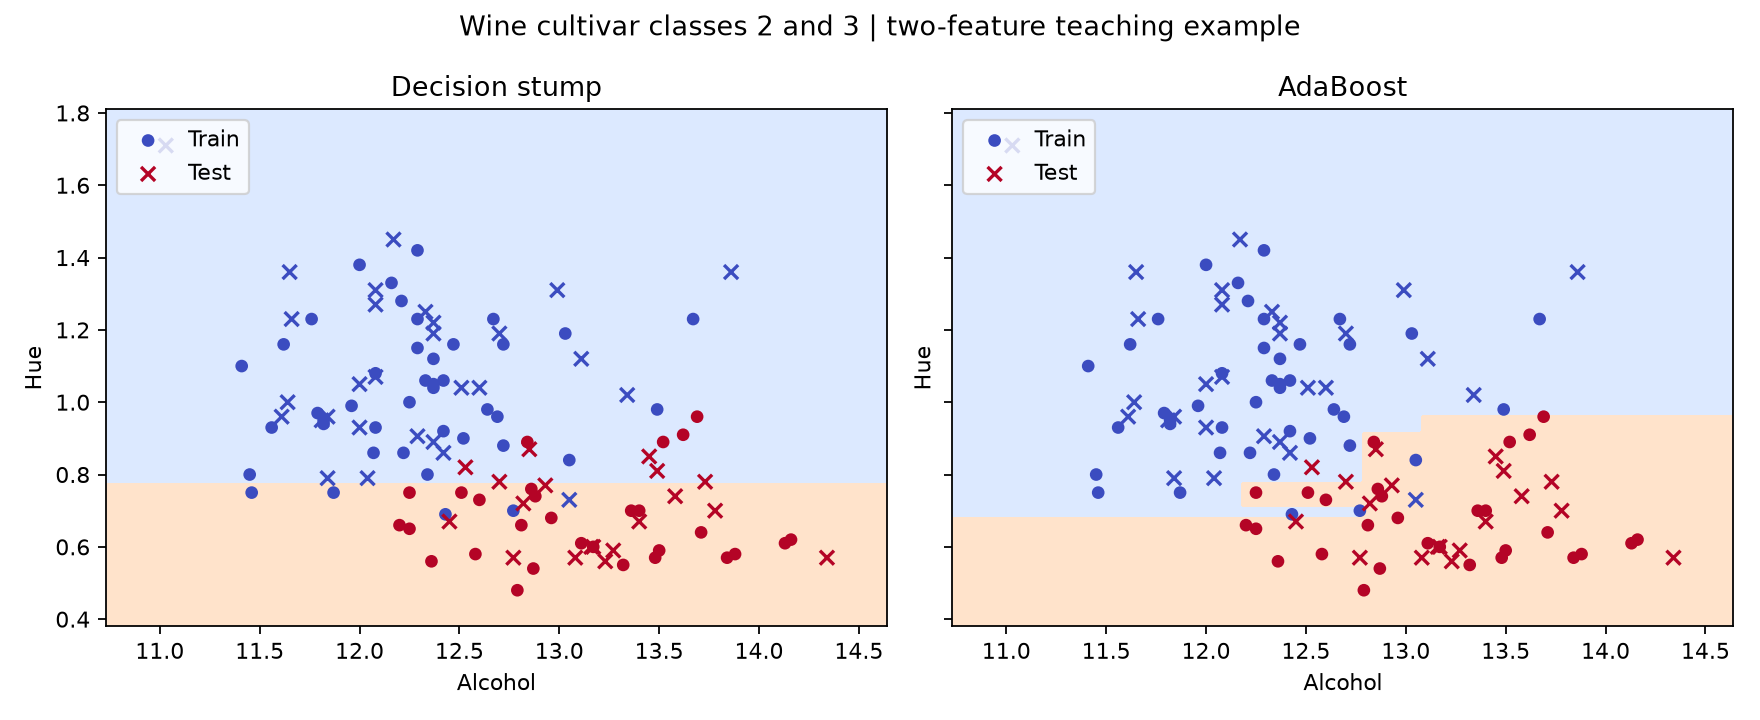

## 6. GBDT：每棵树拟合损失的负梯度

Boosting 的加法模型写为：

$$F_m(x)=F_{m-1}(x)+\eta h_m(x)$$

其中 $\eta$ 是学习率，$h_m$ 是本轮弱学习器。给定损失 $L(y,F)$，本轮在样本点上的伪残差为：

$$r_{im}=-\left[\frac{\partial L(y_i,F(x_i))}{\partial F(x_i)}\right]_{F=F_{m-1}}$$

回归平方损失 $L=\frac12(y-F)^2$ 时，负梯度是 $y_i-F_{m-1}(x_i)$，也就是残差；分类使用 log loss 时，拟合目标是概率损失的负梯度，不是简单的标签差值。

初始回归模型是使总损失最小的常数，平方损失下为 $y$ 的均值。每轮训练一棵浅 CART 回归树拟合伪残差，再把树的输出按学习率加入当前预测。

### 6.1 课程十点回归例子

课程十点数据与第 06 篇回归树相同。初始均值为 `7.307`，随后三棵深度 1 的树依次使用 `6.5、3.5、6.5` 的分裂。

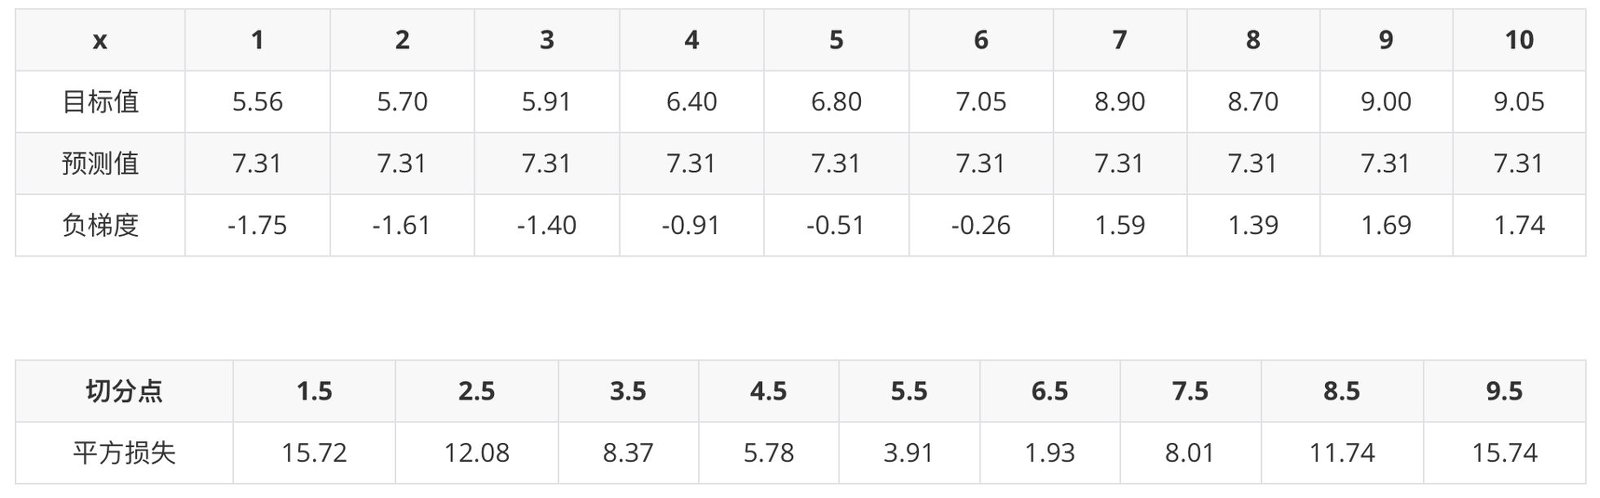

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

X = np.arange(1, 11, dtype=float).reshape(-1, 1)
y = np.array([5.56,5.70,5.91,6.40,6.80,7.05,8.90,8.70,9.00,9.05])
f0 = float(y.mean())
F = np.full(len(y), f0)
trees, gbdt_rounds = [], []
grid = np.linspace(0.5,10.5,800).reshape(-1,1)
grid_F = np.full(len(grid), f0)
curves = [grid_F.copy()]
learning_rate = 1.0  # 便于和课上三轮手算对照
for round_id in range(1,4):
    residual = y - F
    tree = DecisionTreeRegressor(max_depth=1, random_state=22)
    tree.fit(X, residual)
    F += learning_rate * tree.predict(X)
    grid_F += learning_rate * tree.predict(grid)
    trees.append(tree)
    curves.append(grid_F.copy())
    gbdt_rounds.append({"round":round_id,"threshold":float(tree.tree_.threshold[0]),
                        "left_output":float(tree.predict([[1]])[0]),
                        "right_output":float(tree.predict([[10]])[0]),
                        "train_mse":mean_squared_error(y,F)})

gb = GradientBoostingRegressor(loss="squared_error", max_depth=1,
    n_estimators=3, learning_rate=1.0, random_state=22)
gb.fit(X,y)
assert np.allclose(gb.predict(X), F)
gbdt_manual_result = {"f0":f0,"initial_mse":mean_squared_error(y,np.full(len(y),f0)),
                       "rounds":gbdt_rounds,"predictions":F.tolist()}
print(gbdt_manual_result)

fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for i, curve in enumerate(curves):
    axes[0].plot(grid[:,0],curve,label=f"F{i}",linewidth=1.8)
axes[0].scatter(X[:,0],y,c="black",s=25,zorder=5)
axes[0].set(xlabel="x",ylabel="Prediction",title="Constant baseline + residual trees")
axes[0].legend()
axes[1].plot(range(4),[gbdt_manual_result["initial_mse"]]+[r["train_mse"] for r in gbdt_rounds],"o-")
axes[1].set(xlabel="Added trees",ylabel="Training MSE",title="Training loss, not test performance")
for ax in axes: ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
```

这里把学习率设为 1.0，便于复核教师的三轮手算；实际任务通常用较小学习率并增加树的数量。树的输出是对负梯度的分段近似，最终预测为初始常数加上三棵树输出，不能漏掉 $F_0$。

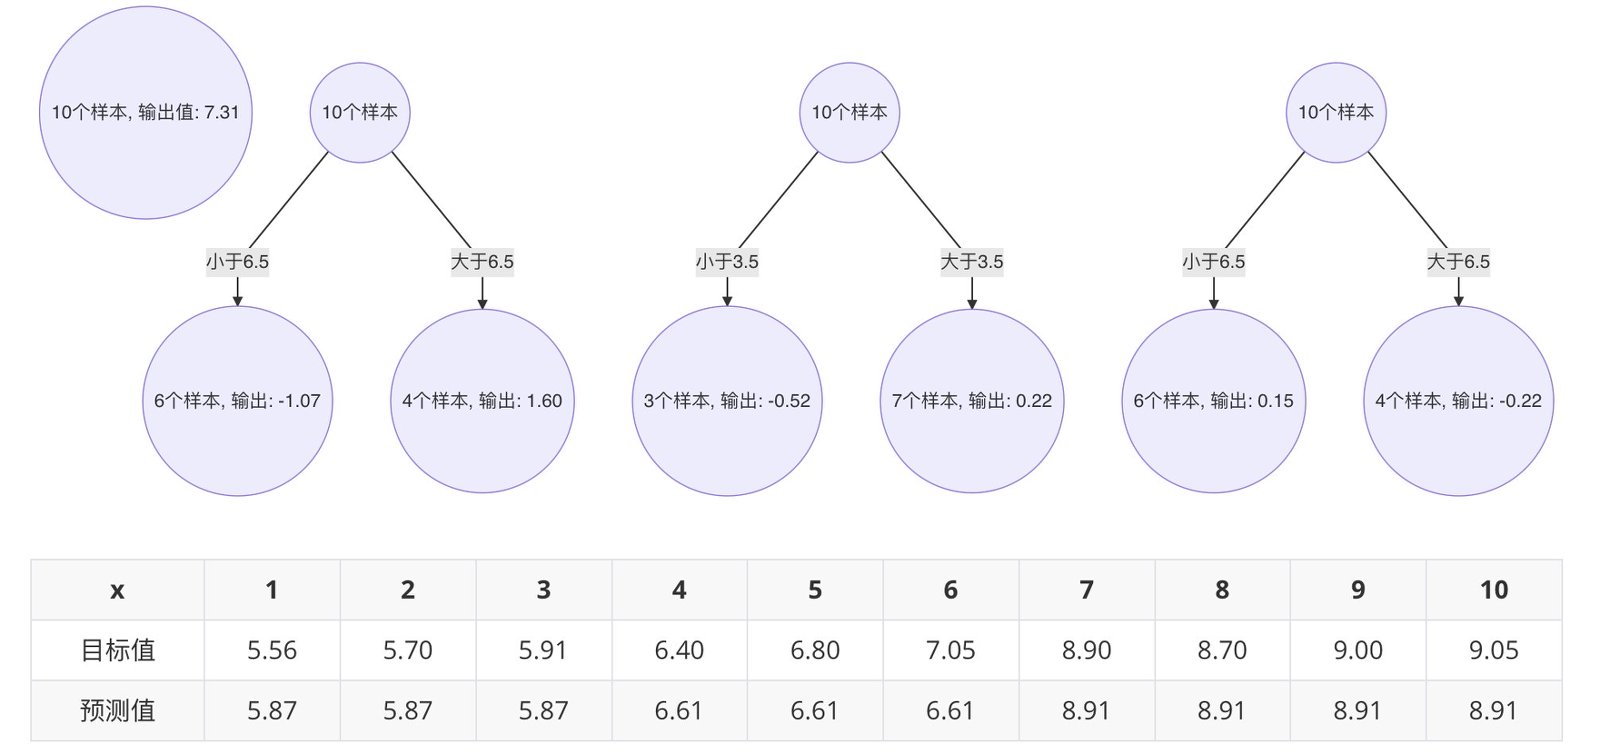

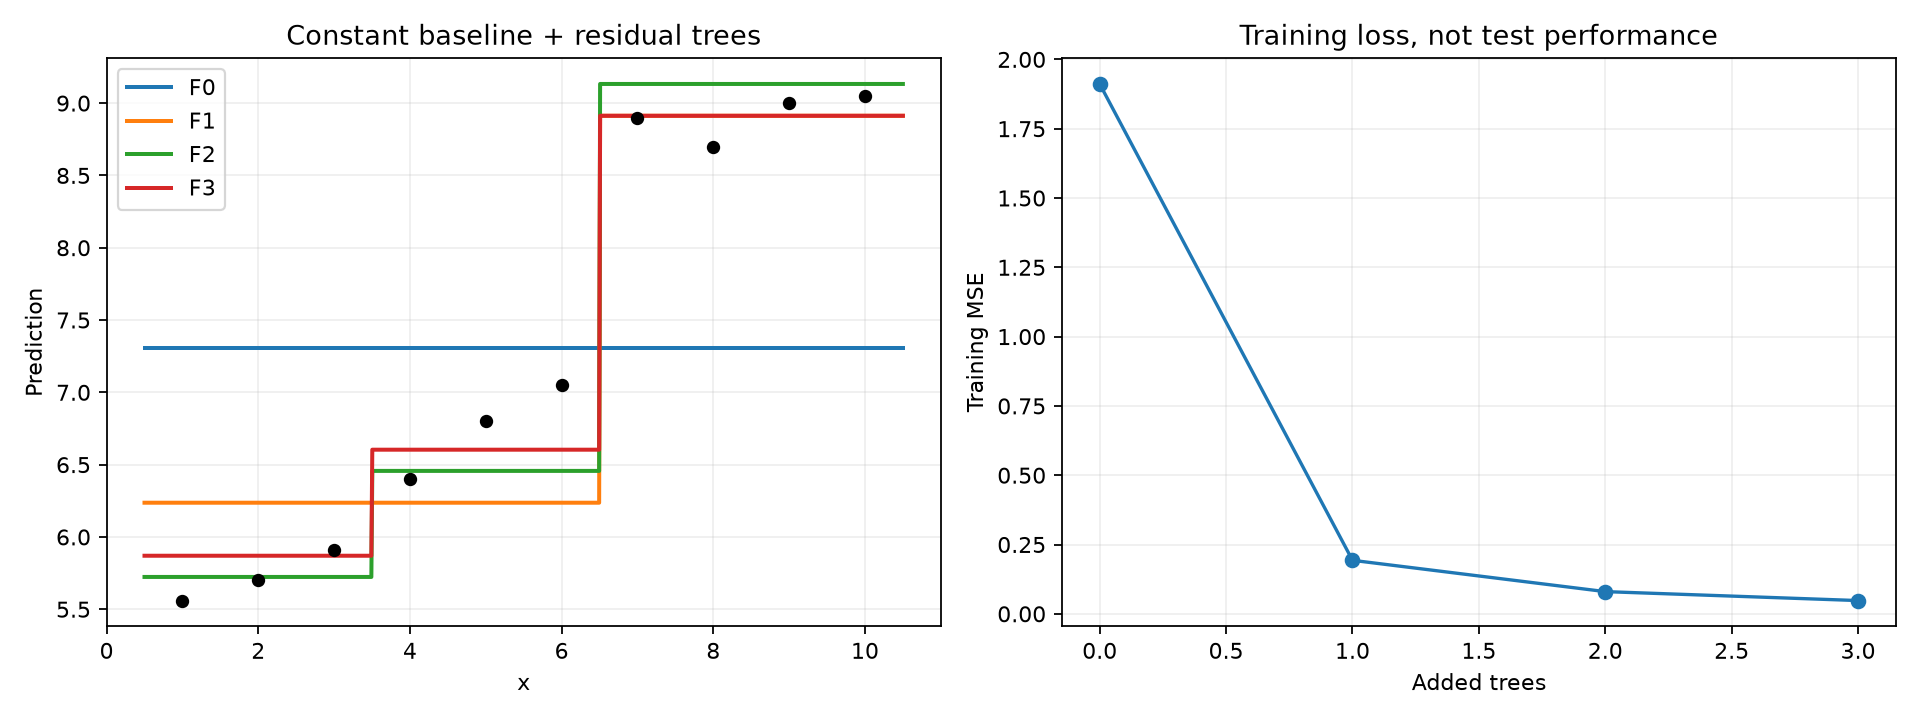

本例的训练 MSE 从约 `1.911421` 降到第三轮约 `0.047801`。第三轮后的三个预测区域输出约为 `5.870000、6.603333、8.912500`；课程图使用近似值，正文和代码采用完整精度。这是训练过程的观察，不是对未知样本泛化误差的保证。

### 6.2 sklearn 的 GBDT API

```python
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

classifier = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=3,
    subsample=0.8,
    random_state=22,
)
regressor = GradientBoostingRegressor(
    loss="squared_error", n_estimators=200,
    learning_rate=0.05, max_depth=2,
    random_state=22,
)
```

`n_estimators` 增加模型容量，`learning_rate` 控制每棵树的贡献，二者通常需要一起调节；`max_depth`、`min_samples_leaf` 控制单棵树复杂度，`subsample<1` 会使用随机子样本形成随机梯度提升。所有选择都应在训练数据内部进行交叉验证。

## 7. XGBoost：带正则化的二阶梯度提升

XGBoost 是对 GBDT 的工程和目标函数改进，核心有三点：

1. 用损失函数二阶泰勒展开，使用一阶导 $g_i$ 和二阶导 $h_i$；
2. 给每棵树增加复杂度正则项；
3. 用由损失和复杂度推导出的分裂增益选择节点。

强学习器为 $\hat y_i^{(t)}=\hat y_i^{(t-1)}+f_t(x_i)$，目标函数可写成：

$$\mathcal L^{(t)}=\sum_i l(y_i,\hat y_i^{(t)})+\sum_{k=1}^{t}\Omega(f_k)$$

$$\Omega(f)=\gamma T+\frac12\lambda\sum_{j=1}^{T}w_j^2$$

$T$ 是叶子数，$w_j$ 是叶子输出值；$\gamma$ 惩罚叶子数量，$\lambda$ 惩罚叶子权重。正则项让训练目标同时考虑拟合和复杂度。

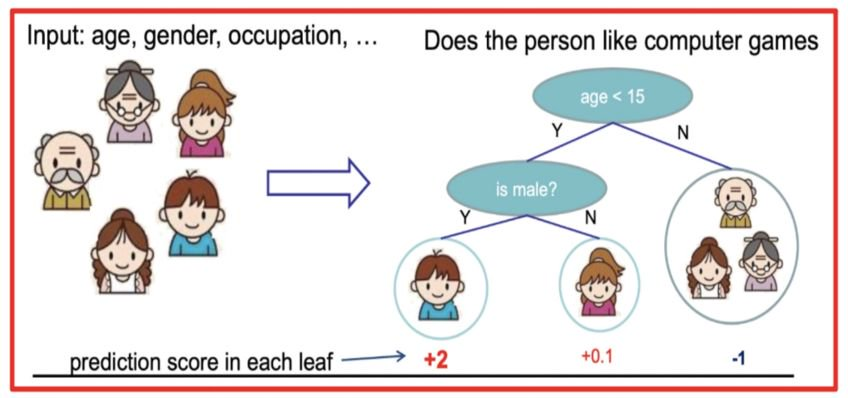

*这张玩具图仅用于说明样本落到叶子后取得一个数值、不同树的输出相加。图中的人物偏好是示例设定，不是本篇实测结论；数值分数也不必直接等于概率。二分类时常需要将累积 margin 再经 sigmoid 转成概率。*

### 7.1 从样本梯度归并到叶子

对上一轮预测附近作二阶近似：

$$l(y_i,\hat y_i+f_t(x_i))\approx l(y_i,\hat y_i)+g_i f_t(x_i)+\frac12h_i f_t(x_i)^2$$

将落到同一叶子的样本聚合，令：

$$G_j=\sum_{i\in I_j}g_i,\qquad H_j=\sum_{i\in I_j}h_i$$

该叶子关于 $w_j$ 的项为：

$$G_jw_j+\frac12(H_j+\lambda)w_j^2$$

求导并令 0，得到叶子最优值：

$$w_j^*=-\frac{G_j}{H_j+\lambda}$$

忽略与当前树无关的常数后，一棵树的评分可写为：

$$-\frac12\sum_{j=1}^{T}\frac{G_j^2}{H_j+\lambda}+\gamma T$$

某候选分裂的增益（左、右子节点分别为 L、R）为：

$$\operatorname{Gain}=\frac12\left(\frac{G_L^2}{H_L+\lambda}+\frac{G_R^2}{H_R+\lambda}-\frac{G^2}{H+\lambda}\right)-\gamma$$

增益大于 0 才值得考虑；`gamma` 越大，越难增加新叶子。公式是仅有 L2 的简化推导，实际还有 L1、叶子约束、学习率和工程搜索策略。

```python
def leaf_weight(G, H, reg_lambda=1.0):
    return -G / (H + reg_lambda)

def split_gain(G_left, H_left, G_right, H_right, reg_lambda=1.0, gamma=0.0):
    parent = (G_left + G_right) ** 2 / (H_left + H_right + reg_lambda)
    children = (G_left ** 2 / (H_left + reg_lambda)
                + G_right ** 2 / (H_right + reg_lambda))
    return 0.5 * (children - parent) - gamma

print("左叶最优值：", leaf_weight(-4, 2))
print("右叶最优值：", leaf_weight(4, 2))
print("gain(gamma=0)：", split_gain(-4, 2, 4, 2))
print("gain(gamma=6)：", split_gain(-4, 2, 4, 2, gamma=6))
```

### 7.2 XGBoost API 参数

```python
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    objective="multi:softprob",
    eval_metric="mlogloss",
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    gamma=0.0,
    early_stopping_rounds=20,
    random_state=22,
)
```

| 参数 | 作用 |
| --- | --- |
| `n_estimators` | 最大 boosting 轮数；早停可能提前结束 |
| `learning_rate` | 每棵树贡献的缩放 |
| `max_depth` | 每棵树最大深度 |
| `min_child_weight` | 子节点继续分裂所需的 Hessian 权重 |
| `subsample`、`colsample_bytree` | 行和列的随机采样比例 |
| `reg_lambda`、`reg_alpha` | L2、L1 正则强度 |
| `gamma` | 新切分所需的最小损失下降 |
| `objective` | 任务和输出形式；多分类概率使用 `multi:softprob` |
| `eval_metric` | 训练过程监控指标；应与任务目标匹配 |

多分类目标要从 0 到 `num_class-1` 连续编码；sklearn 包装器可从训练类别推断类别数。`multi:softmax` 的原生输出是硬类别，本篇使用 `multi:softprob` 明确输出概率。`min_child_weight` 是 Hessian 权重和阈值，不能简单当成叶子最少样本数。

本篇用关键词传参，省略已过时的 `use_label_encoder=False`；在当前 XGBoost 中把 `early_stopping_rounds` 放在构造器中，并通过 `fit(eval_set=...)` 传入验证集。

### 7.3 多分类 XGBoost 的安全训练函数

```python
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, f1_score, log_loss
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

def train_xgb_multiclass(X, labels, balanced=False):
    """数值特征的多分类训练：fit/early-stop-validation/test。"""
    X = pd.DataFrame(X).copy()
    X.columns = [str(c) for c in X.columns]
    if not X.columns.is_unique:
        raise ValueError("特征列名不能重复")
    X = X.apply(pd.to_numeric, errors="raise").replace([np.inf,-np.inf],np.nan)
    labels = np.asarray(labels)
    if pd.isna(labels).any():
        raise ValueError("目标含有缺失标签")
    X_dev, X_test, labels_dev, labels_test = train_test_split(
        X, labels, test_size=0.2, stratify=labels, random_state=22)
    X_fit, X_valid, labels_fit, labels_valid = train_test_split(
        X_dev, labels_dev, test_size=0.25, stratify=labels_dev, random_state=22)
    encoder = LabelEncoder().fit(labels_fit)
    if len(encoder.classes_) < 3:
        raise ValueError("本函数用于至少3类的多分类；二分类请使用binary:logistic")
    known = set(encoder.classes_)
    if not set(labels_valid).issubset(known) or not set(labels_test).issubset(known):
        raise ValueError("验证或测试出现训练未见类别，请检查切分")
    y_fit, y_valid, y_test = map(encoder.transform, [labels_fit,labels_valid,labels_test])
    model = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
        objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
        reg_lambda=1.0, subsample=0.8, colsample_bytree=0.8,
        early_stopping_rounds=20, random_state=22, n_jobs=1)
    weights = compute_sample_weight("balanced",y_fit) if balanced else None
    model.fit(X_fit,y_fit, sample_weight=weights,
              eval_set=[(X_fit,y_fit),(X_valid,y_valid)],verbose=False)
    # eval_set最后一组用于early stopping；测试集没有传入fit
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)
    print(classification_report(y_test,pred,labels=np.arange(len(encoder.classes_)),
        target_names=[str(c) for c in encoder.classes_],digits=4,zero_division=0))
    result = {"fit_size":len(y_fit),"valid_size":len(y_valid),"test_size":len(y_test),
              "class_mapping":{str(c):int(i) for i,c in enumerate(encoder.classes_)},
              "best_iteration":int(model.best_iteration),
              "test_accuracy":accuracy_score(y_test,pred),
              "test_macro_f1":f1_score(y_test,pred,average="macro"),
              "test_log_loss":log_loss(y_test,prob,labels=np.arange(len(encoder.classes_)))}
    print(result)
    return {"model":model,"label_encoder":encoder,"feature_names":list(X.columns),
            "result":result,"evals":model.evals_result()}
```

函数把开发数据再切成 fit、validation、test：早停只看 validation，test 只在最后计算一次。类别映射由 fit 标签拟合；验证或测试出现训练未见类别时直接报错，避免静默产生错误标签。

## 8. XGBoost 补充实战：Wine 内置数据

下面使用 sklearn 的 `load_wine()`，目标是 3 种葡萄酒产区，不是课程的“红酒品质”标签。它用于验证多分类、概率输出、早停和损失曲线；不会冒充课程 CSV 的效果。

```python
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

# 先运行上一节 train_xgb_multiclass；这里是产区类别，不是红酒品质
wine = load_wine()
X_wine = pd.DataFrame(wine.data,columns=wine.feature_names)
offline_xgb = train_xgb_multiclass(X_wine,wine.target)
fig, ax = plt.subplots(figsize=(9,4.5))
evals = offline_xgb["evals"]
ax.plot(evals["validation_0"]["mlogloss"],label="Fit")
ax.plot(evals["validation_1"]["mlogloss"],label="Early-stop validation")
ax.axvline(offline_xgb["result"]["best_iteration"],color="#c87a22",linestyle="--",label="Best iteration")
ax.set(xlabel="Boosting iteration (zero-based)",ylabel="Multiclass log loss",
       title="XGBoost Wine cultivar demo | test set held out")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()
```

| 指标 | 实际值 |
| --- | --- |
| fit / validation / test | 106 / 36 / 36 |
| best_iteration（从0开始） | 267 |
| 测试 accuracy | 0.972222 |
| 测试 macro-F1 | 0.971781 |
| 测试 log loss | 0.193239 |

这次固定切分的测试 accuracy 约 `0.9722`，macro-F1 约 `0.9718`，`best_iteration=267`。迭代编号从 0 开始，对应 268 轮；当前 sklearn 接口预测时默认使用最佳迭代范围。数值会随版本和参数变化，应把它看作流程检查结果。

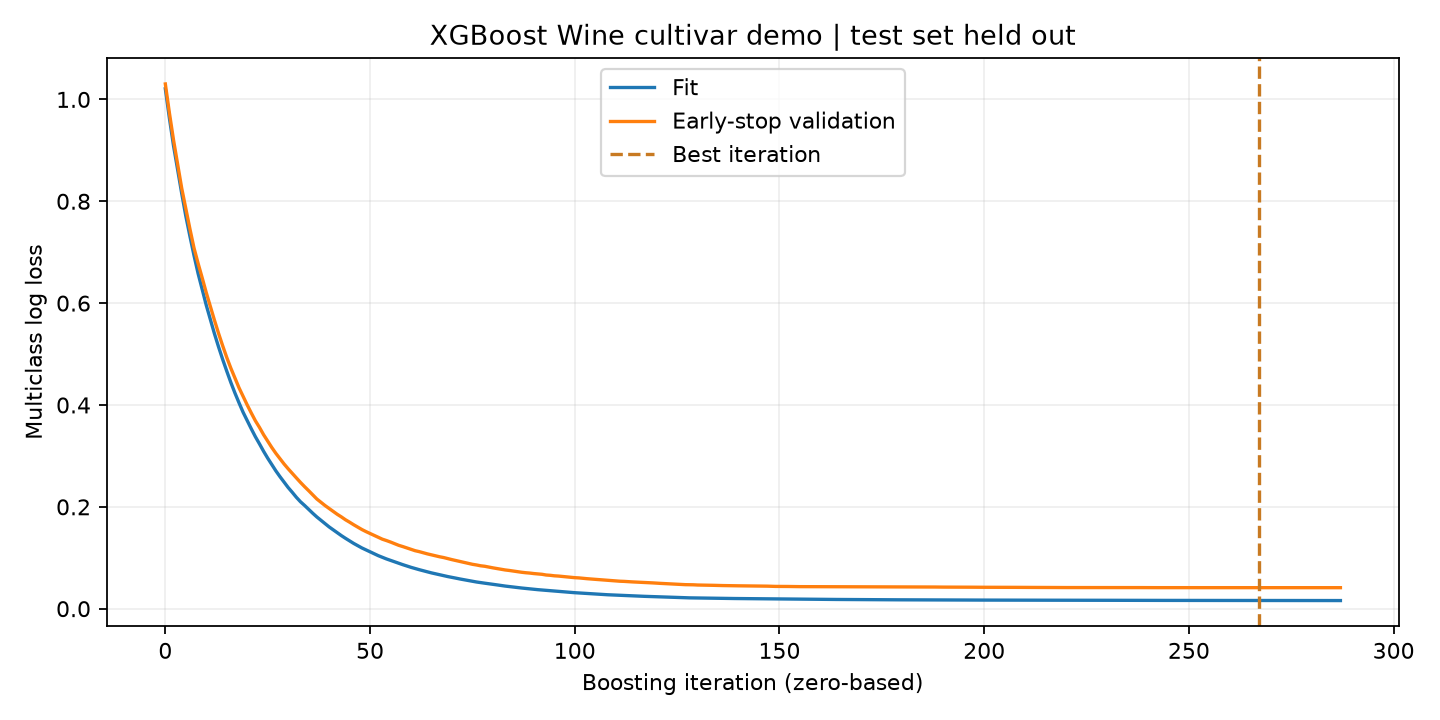

早停在验证指标连续指定轮数未改善时停止，不要求每轮回升。曲线可帮助判断训练过程，不能通过查看测试曲线选择轮数。早停验证集被用于选择迭代次数，因此最终仍要保留独立测试集。

## 9. 课程红酒品质数据：先检查 schema，再训练

教师笔记中的文件名是 `红酒品质分类.csv`，描述为数值特征和质量标签；正文“6 类”和列出的编号数量不一致，源码又把标签减 3。本篇不推断实际行数、标签范围或是否已经重编码，必须以 CSV 检查结果为准。这里用 `LabelEncoder` 保存明确映射，避免盲目执行 `y-3`。

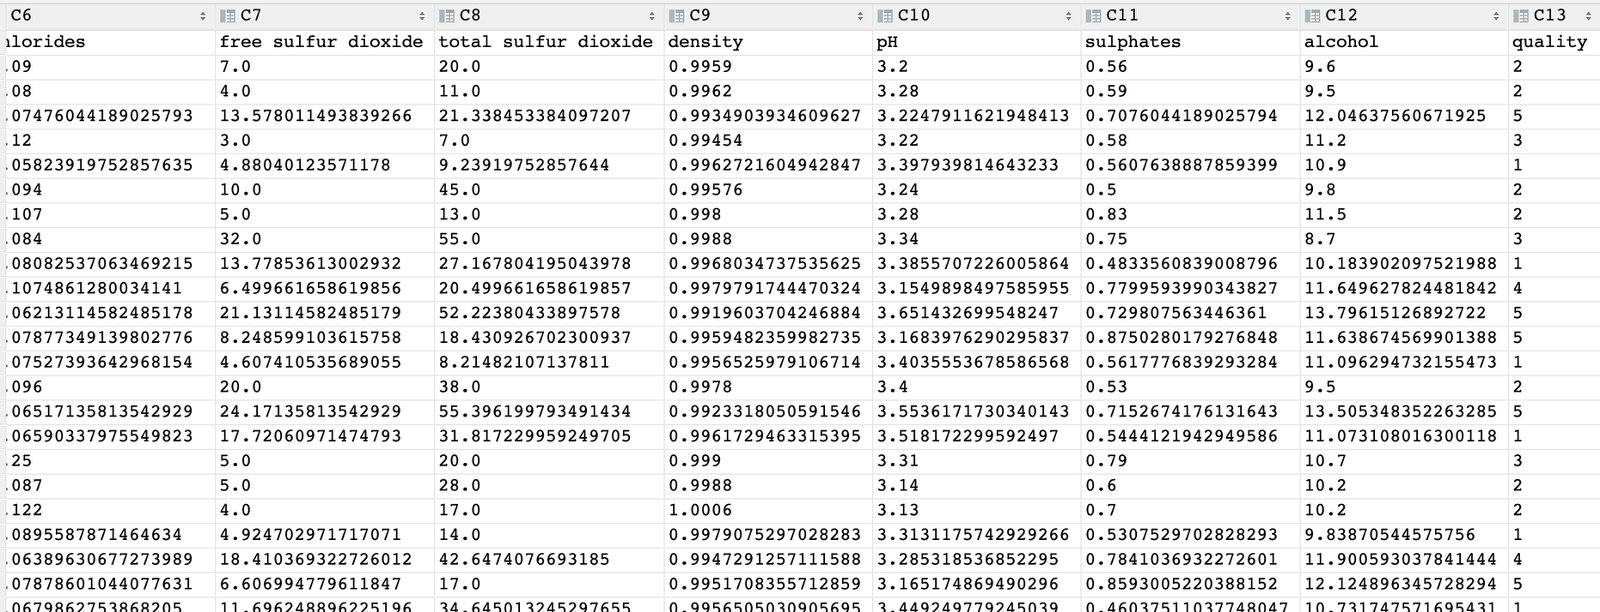

运行前检查：

```python
import pandas as pd

wine = pd.read_csv("data/红酒品质分类.csv")
wine.columns = [str(c).strip() for c in wine.columns]
print(wine.shape)
print(wine.dtypes)
print(wine.isna().sum().sort_values(ascending=False).head())
print(wine.iloc[:, -1].value_counts(dropna=False).sort_index())
```

确认目标列后，按实际列名传入下一段函数。数据文件可能包含导出索引列 `Unnamed: 0`，它不是有效特征；质量标签是有序等级时，普通多分类把等级间距当成类别区别，若业务需要有序预测应单独设计目标和评价。

### 9.1 课程 CSV 的多分类入口

```python
import pandas as pd

# 先运行 train_xgb_multiclass；按实际课程文件检查分隔符、列名与标签
wine_quality = pd.read_csv("data/红酒品质分类.csv")
wine_quality.columns = [str(c).strip() for c in wine_quality.columns]
print(wine_quality.shape, wine_quality.columns.tolist())
print(wine_quality["quality"].value_counts(dropna=False).sort_index())
# 导出时产生的Unnamed索引列不是特征
wine_quality = wine_quality.loc[:,~wine_quality.columns.str.startswith("Unnamed:")]
feature_names = ["fixed acidity","volatile acidity","citric acid","residual sugar",
                 "chlorides","free sulfur dioxide","total sulfur dioxide","density",
                 "pH","sulphates","alcohol"]
missing = set(feature_names + ["quality"]) - set(wine_quality.columns)
if missing:
    raise ValueError(f"请核对实际CSV列名，缺少：{sorted(missing)}")
quality_bundle = train_xgb_multiclass(
    wine_quality[feature_names], wine_quality["quality"].to_numpy(), balanced=False)
```

这段代码会检查 11 个常见化学属性列和 `quality` 目标。若课程文件列名是中文或不同版本，先建立明确映射再调用函数；不要静默按位置取列。

样本不均衡可以用 `compute_sample_weight("balanced", y_fit)` 传给 `fit`，也可以调整评价指标，但要在验证集上确认是否真的改善少数质量等级的 recall。网格搜索应只在开发数据完成，不能用测试集挑参数。

### 9.2 保存模型时一起保存输入契约

```python
from pathlib import Path
import json

def save_model_bundle(model, feature_names, class_mapping, directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    model.save_model(directory / "xgboost.json")
    (directory / "metadata.json").write_text(json.dumps({
        "feature_names": feature_names,
        "class_mapping": class_mapping,
    }, ensure_ascii=False, indent=2), encoding="utf-8")
```

不要只保存一个模型文件而忘记特征顺序、类别映射和预处理规则；上线时输入契约必须和训练时一致。

```python
from pathlib import Path
import json

def save_xgb_bundle(bundle, directory):
    directory = Path(directory)
    directory.mkdir(parents=True,exist_ok=True)
    bundle["model"].save_model(directory / "xgboost.json")
    metadata = {"feature_names":bundle["feature_names"],
                "class_mapping":bundle["result"]["class_mapping"],
                "best_iteration":bundle["result"]["best_iteration"],
                "result":bundle["result"]}
    (directory / "metadata.json").write_text(
        json.dumps(metadata,ensure_ascii=False,indent=2),encoding="utf-8")

# 实际使用时执行下面一行，课程例子用quality_bundle
# save_xgb_bundle(quality_bundle, "model/wine_quality_xgb")
```

## 10. 四种方法怎样选择

| 场景 | 起步模型 | 需要重点验证 |
| --- | --- | --- |
| 表格分类、希望稳健基线 | 随机森林 | 类别不平衡、OOB/CV、特征重要性偏差 |
| 关注难样本，基分类器很弱 | AdaBoost | 噪声敏感性、学习轮数、样本权重 |
| 表格数据，需要较强预测力 | GBDT / XGBoost | 学习率、树深、早停、正则化 |
| 需要并行训练很多独立模型 | Bagging / 随机森林 | 内存、线程、树之间相关性 |
| 希望概率可解释 | 概率输出＋校准 | Brier/log loss、校准曲线、独立验证 |

树集成通常不要求标准化，但仍需处理类别、缺失、目标泄漏和切分策略。GBDT/XGBoost 的训练是串行的，树数量和早停会影响训练时间；随机森林各树更容易并行。

模型选择的优先级应来自任务代价：准确率、macro-F1、少数类 recall、ROC-AUC、log loss 和预测延迟可能给出不同排序。先确定主指标，再在同一验证方案下比较。

## 11. 易错点对照

| 错误理解 | 正确说法 |
| --- | --- |
| 树越多一定越好 | 误差通常趋于稳定，但成本、相关错误和过拟合仍需验证 |
| Bagging 和 Boosting 都是随机抽样 | Bagging 的核心是 bootstrap；Boosting 重点是串行关注错误 |
| 随机森林每棵树都看全部特征 | 标准随机森林在节点还会随机抽取候选特征 |
| OOB 分数就是测试集分数 | OOB 是训练过程留下样本的近似验证估计 |
| 不放回抽样会让不同树的数据没有交集 | 每棵树分别抽样时依然可能重叠；只有刻意划成互斥子集才没有交集 |
| 错分样本权重变大后就删除正确样本 | AdaBoost 保留所有样本，只改变相对权重 |
| AdaBoost 的模型权重等于样本权重 | $\alpha_t$ 衡量基学习器，$D_t(i)$ 衡量样本 |
| GBDT 每轮都拟合原始 y | 每轮拟合当前损失的负梯度；平方损失才是残差 |
| XGBoost 只是把树数量调大 | 它还用二阶近似、叶子正则和分裂增益 |
| `multi:softmax` 能直接算 log loss | 它只输出硬类别；概率指标需要 `multi:softprob` |
| 用测试集早停不会影响评估 | 早停选择迭代次数也会适配测试集，必须留 validation |
| 课程代码的准确率可以直接复现 | 数据路径、版本和切分要一致；本篇未取得课程 CSV |

## 12. 复习与练习

1. 证明 bootstrap 抽样中某条样本未出现的概率趋近 $e^{-1}$，解释 63.2% 规则。
2. 构造三棵树的概率，使硬投票和软投票输出不同，并说明业务上更愿意保留哪种信息。
3. 手算 AdaBoost 第一轮：$\epsilon=0.3$ 时 $\alpha$ 是多少？错分样本归一化后的权重是多少？
4. 将 AdaBoost 代码中的阈值方向从 `1` 改为 `-1`，检查何时能降低错误率。
5. 用第 06 篇十点数据手算 GBDT 第一轮的初始均值和残差，比较深度 1 与深度 2 的训练损失。
6. 对 XGBoost 的四个 $G/H$ 数值改变 `lambda` 和 `gamma`，观察叶子值与分裂增益怎样变化。
7. 为随机森林、GBDT、XGBoost 设计同一个 validation/test 切分，比较 macro-F1、log loss 和训练时间。
8. 读取课程红酒 CSV 后，先检查目标分布，再决定是否需要 sample weight；不要先写死 `y-3`。

能够回答下面四句，说明主线已经掌握：随机森林通过样本和特征随机性降低相关方差；AdaBoost 增大难样本权重并给好基学习器更大权重；GBDT 每轮拟合损失负梯度；XGBoost 在此基础上用二阶导数和正则化控制树的复杂度。

## 13. 资料与验证范围

原课依据：`07_集成学习/02-笔记/集成学习.md`、其中的课堂图片和代码目录。课程 `day07.zip` 下载未成功，课程 Titanic 与红酒品质 CSV 未在本轮真实运行；Notebook 明确区分了课程代码、补充代码和合成数据验证。

本轮离线验证：

- bootstrap/OOB 概率和 AdaBoost 三轮样本权重；
- 乳腺癌数据上的单树、Bagging、随机森林和交叉验证；
- 内置 Wine 两类 AdaBoost；
- 十点回归数据的 GBDT 三轮残差树；
- 内置 Wine 多分类 XGBoost、早停、概率指标和模型保存/加载；
- 合成 Titanic 与红酒品质表的输入检查和 Pipeline 结构。

环境版本：sklearn 1.9.1、NumPy 2.5.4、pandas 3.0.6、XGBoost 3.4.1。不同版本可能更改默认参数或输出格式，请以当前环境文档为准。

可查阅：[sklearn Ensemble 用户指南](https://scikit-learn.org/stable/modules/ensemble.html)、[RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)、[GradientBoosting](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting)、[XGBoost Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html)。